# Phase 1.5 Session 1: BBBC038 batch processing + diameter sweep

Goal: (1) Run the Cellpose nuclei pipeline on all 65 BBBC038 test images in a
single loop (batch processing) instead of image-by-image. (2) Test how the
`diameter` parameter changes segmentation results (nucleus count, mean area).

Method: Colab + T4 GPU, cellpose<4, model_type='nuclei', channels=[0, 0].
Per-nucleus quantification with scikit-image regionprops_table
(area, perimeter, eccentricity, mean_intensity, circularity = 4π·area/perimeter²).
Diameter sweep on the first 6 images: diameter = None (model estimate), 10, 20, 30 px.

In [4]:
%pip install -q "cellpose<4"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
jax 0.11.1 requires numpy>=2.1, but you have numpy 2.0.2 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 2.0.2 which is incompatible.
dm-tree 0.1.10 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 2.0.2 which is incompatible.


In [5]:
!wget -q https://data.broadinstitute.org/bbbc/BBBC038/stage1_test.zip -O /content/stage1_test.zip
!unzip -q -o /content/stage1_test.zip -d /content/bbbc038
import glob
img_files = sorted(glob.glob('/content/bbbc038/*/images/*.png'))
print(len(img_files), 'images downloaded')

65 images downloaded


In [6]:
from cellpose import models
from skimage import io
import numpy as np

model = models.CellposeModel(gpu=True, model_type='nuclei')

def load_gray(path):
    im = io.imread(path)
    if im.ndim == 3:              # RGB/RGBA → グレースケール化
        im = im[..., :3].mean(axis=-1)
    return im

100%|██████████| 25.3M/25.3M [00:00<00:00, 69.6MB/s]


In [7]:
from skimage import measure
import pandas as pd
import time

t0 = time.time()
tables, summary = [], []
for k, f in enumerate(img_files):
    g = load_gray(f)
    m, _, _ = model.eval(g, channels=[0, 0])   # diameter=None = モデルの自動推定
    iid = f.split('/')[-3][:12]
    props = measure.regionprops_table(
        m.astype(int), intensity_image=g,
        properties=('label', 'area', 'perimeter', 'eccentricity', 'mean_intensity'))
    df = pd.DataFrame(props)
    df['image_id'] = iid
    tables.append(df)
    summary.append({'image_id': iid, 'n_nuclei': int(m.max()),
                    'mean_area': df['area'].mean()})
    if (k + 1) % 10 == 0:
        print(k + 1, '/ 65 done')

quant_all = pd.concat(tables, ignore_index=True)
quant_all['circularity'] = 4 * 3.14159 * quant_all['area'] / quant_all['perimeter']**2
summary_df = pd.DataFrame(summary)
print('total nuclei:', len(quant_all))
print('elapsed: %.1f sec' % (time.time() - t0))
summary_df.head(10)

/usr/local/lib/python3.13/dist-packages/cellpose/dynamics.py:760: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


10 / 65 done
20 / 65 done
30 / 65 done


40 / 65 done
50 / 65 done


60 / 65 done
total nuclei: 2350
elapsed: 164.2 sec


,image_id,n_nuclei,mean_area
0,0114f484a16c,3,184.000000
1,0999dab07b11,55,457.109091
2,0a849e0eb15f,39,361.538462
3,0e132f71c8b4,2,137.000000
4,0ed3555a4bd4,1,96.000000
5,0f1f896d9ae5,30,1762.833333
6,1747f62148a9,19,1277.421053
7,17b9bf4356db,3,1843.333333
8,1879f4f4f05e,9,902.111111
9,191b2b2205f2,7,189.285714


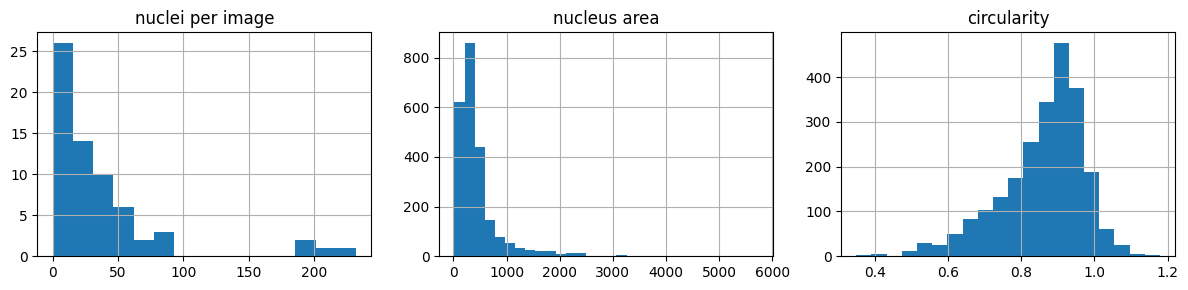

         n_nuclei    mean_area
count   65.000000    60.000000
mean    36.153846   587.713021
std     49.798102   465.335439
min      0.000000    79.800000
25%      6.000000   196.102679
50%     21.000000   437.820674
75%     45.000000   904.307018
max    232.000000  1843.333333


In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
summary_df['n_nuclei'].hist(bins=15, ax=axes[0]); axes[0].set_title('nuclei per image')
quant_all['area'].hist(bins=30, ax=axes[1]); axes[1].set_title('nucleus area')
quant_all['circularity'].hist(bins=20, ax=axes[2]); axes[2].set_title('circularity')
plt.tight_layout()
plt.savefig('/content/bbbc038_batch_summary.png', dpi=150)
plt.show()
print(summary_df.describe())

In [9]:
diameters = [None, 10, 20, 30]
rows = []
sweep_masks = {}   # 後で図にするため、画像0のマスクだけ保持
for d in diameters:
    total_n, areas = 0, []
    for i, f in enumerate(img_files[:6]):
        g = load_gray(f)
        m, _, _ = model.eval(g, diameter=d, channels=[0, 0])
        total_n += int(m.max())
        areas.append(measure.regionprops_table(m.astype(int), properties=('area',))['area'])
        if i == 0:
            sweep_masks[d] = m
    all_areas = np.concatenate(areas)
    rows.append({'diameter': str(d), 'total_nuclei_6imgs': total_n,
                 'mean_area': all_areas.mean()})
    print('diameter', d, '-> nuclei(6 imgs):', total_n, ', mean area: %.1f' % all_areas.mean())

sweep_df = pd.DataFrame(rows)
sweep_df

diameter None -> nuclei(6 imgs): 130 , mean area: 715.8
diameter 10 -> nuclei(6 imgs): 122 , mean area: 242.7
diameter 20 -> nuclei(6 imgs): 135 , mean area: 447.7
diameter 30 -> nuclei(6 imgs): 130 , mean area: 715.8


,diameter,total_nuclei_6imgs,mean_area
0,None,130,715.753846
1,10,122,242.663934
2,20,135,447.740741
3,30,130,715.753846


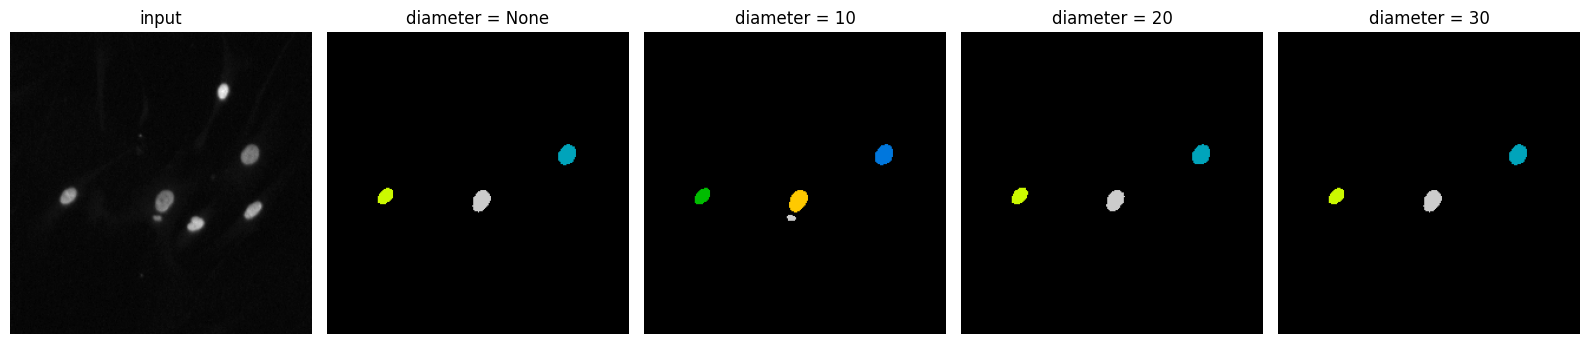

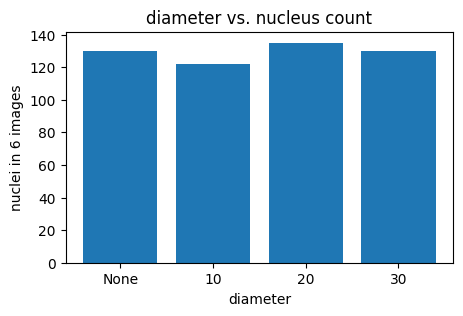

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
g0 = load_gray(img_files[0])
axes[0].imshow(g0, cmap='gray'); axes[0].set_title('input'); axes[0].axis('off')
for j, d in enumerate(diameters):
    axes[j + 1].imshow(sweep_masks[d], cmap='nipy_spectral')
    axes[j + 1].set_title('diameter = %s' % d); axes[j + 1].axis('off')
plt.tight_layout()
plt.savefig('/content/bbbc038_diameter_sweep.png', dpi=150)
plt.show()

plt.figure(figsize=(5, 3))
plt.bar(sweep_df['diameter'], sweep_df['total_nuclei_6imgs'])
plt.xlabel('diameter'); plt.ylabel('nuclei in 6 images')
plt.title('diameter vs. nucleus count')
plt.show()


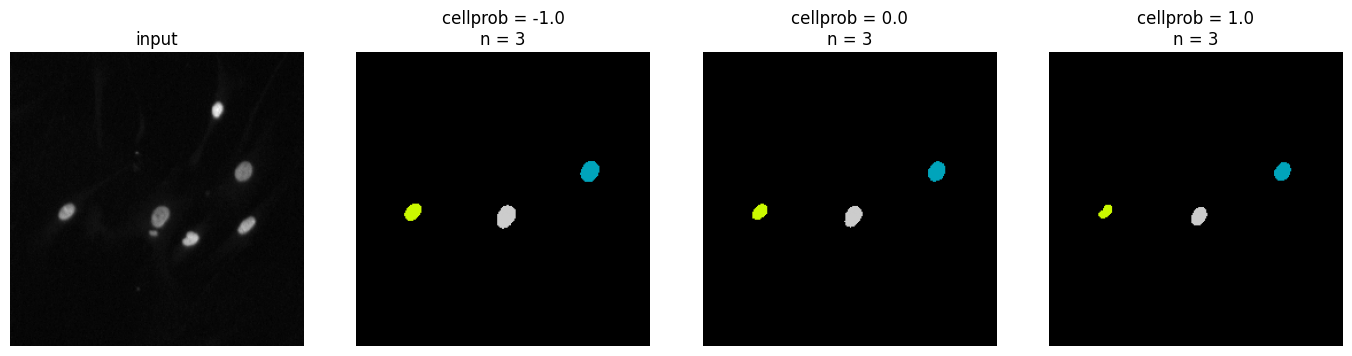

In [11]:
cps = [-1.0, 0.0, 1.0]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
g0 = load_gray(img_files[0])
axes[0].imshow(g0, cmap='gray'); axes[0].set_title('input'); axes[0].axis('off')
for j, cp in enumerate(cps):
    m, _, _ = model.eval(g0, channels=[0, 0], cellprob_threshold=cp)
    axes[j + 1].imshow(m, cmap='nipy_spectral')
    axes[j + 1].set_title('cellprob = %s\nn = %d' % (cp, int(m.max()))); axes[j + 1].axis('off')
plt.tight_layout(); plt.show()

In [12]:
quant_all.to_csv('/content/bbbc038_batch_quantification.csv', index=False)
summary_df.to_csv('/content/bbbc038_batch_per_image.csv', index=False)
from google.colab import files
files.download('/content/bbbc038_batch_quantification.csv')
files.download('/content/bbbc038_batch_per_image.csv')
files.download('/content/bbbc038_batch_summary.png')
files.download('/content/bbbc038_diameter_sweep.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>